# Project 01: Seed-based Graph Matching with Seeded Graph Matching (SGM)

**Goal:** recover the one-to-one mapping between anonymized graph A and auxiliary graph B (B is A with some edges deleted and replaced by random ones), starting from a small set of known seed pairs.

**Method (own implementation, numpy/scipy only, no graph-matching libraries).** Search for the mapping that makes the two edge sets agree as much as possible:

`maximise  f(P) = trace(A P B P^T)`  over permutation matrices `P` that contain the seed pairs.

Writing `P` as a fixed seed block plus an unknown block `X` over the unseeded nodes, the problem is relaxed to doubly-stochastic `X` and solved with **Frank-Wolfe**: each iteration computes the gradient `G = A P B`, solves one `linear_sum_assignment` on the unseeded block of `G` to get a direction, takes the exact line-search step (the objective is quadratic along the segment) and moves. At the end `X` is projected back to a permutation with one more assignment. The problem is non-convex, so the **initialisation** is tuned: barycentre (uniform `X`), the permutation implied by the seed votes, or a 50/50 mix. Each match gets a confidence `score` = number of agreeing neighbour pairs under the final mapping.

**Protocol:** tune only on Train, confirm on Val, freeze the configuration in `config.json`, then predict Test. Test truth is never read.

**Notebook map:** 1 Setup, 2 SGM, 3 Experiment helpers, 4 Tuning and freeze, 5 SGM results, 6 Confidence and optimum check, 7 Test predictions, 8 Comparison with other methods, Takeaways.

## 1. Setup, data loading and metrics
Graphs are symmetric 0/1 sparse CSR matrices; seeds and truth are `{node_a: node_b}` dicts. Precision = correct / predicted, recall = correct / n, F1, coverage = predicted / n. Seeds are given for free, so every metric is also reported on **unseeded** nodes only. Metrics are computed per graph instance and then averaged over instances (never pooled over nodes).

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from scipy.optimize import linear_sum_assignment

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
DATA = Path('student/seed_based')
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)
FIGS = RESULTS / 'figs'; FIGS.mkdir(exist_ok=True)

In [2]:
def build_adj(edges, n):
    """Symmetric 0/1 CSR adjacency, no self-loops."""
    m = sp.coo_matrix((np.ones(len(edges)), (edges.source, edges.target)), shape=(n, n))
    m = (m + m.T).tocsr()
    m.setdiag(0)
    m.eliminate_zeros()
    m.data[:] = 1.0
    return m


def load_instance(split, name, seed_kind="random", seed_pct=5):
    d = DATA / split / name
    n_a = len(pd.read_csv(d / "nodes_a.csv"))
    n_b = len(pd.read_csv(d / "nodes_b.csv"))
    A = build_adj(pd.read_csv(d / "edges_a.csv"), n_a)
    B = build_adj(pd.read_csv(d / "edges_b.csv"), n_b)
    seeds = pd.read_csv(d / f"seeds_{seed_kind}_{seed_pct:02d}.csv")
    seeds = dict(zip(seeds.node_a, seeds.node_b))
    gt = d / "ground_truth.csv"
    truth = None
    if gt.exists():
        t = pd.read_csv(gt)
        truth = dict(zip(t.node_a, t.node_b))
    meta = json.loads((d / "metadata.json").read_text())
    return A, B, seeds, truth, meta


def list_instances(split):
    return sorted(p.name for p in (DATA / split).iterdir() if p.is_dir())


def evaluate(pred, truth, seeds, n):
    """P/R/F1/coverage, overall and unseeded-only."""
    correct = sum(truth.get(a) == b for a, b in pred.items())
    p = correct / len(pred) if pred else 0.0
    r = correct / n
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    un_pred = {a: b for a, b in pred.items() if a not in seeds}
    un_truth_n = n - len(seeds)
    un_correct = sum(truth.get(a) == b for a, b in un_pred.items())
    un_p = un_correct / len(un_pred) if un_pred else 0.0
    un_r = un_correct / un_truth_n if un_truth_n else 0.0
    un_f1 = 2 * un_p * un_r / (un_p + un_r) if un_p + un_r else 0.0
    return dict(
        precision=p, recall=r, f1=f1, coverage=len(pred) / n,
        unseeded_precision=un_p, unseeded_recall=un_r, unseeded_f1=un_f1,
        unseeded_coverage=len(un_pred) / un_truth_n if un_truth_n else 0.0,
    )


print({s: len(list_instances(s)) for s in ['train', 'val', 'test']})

{'train': 27, 'val': 9, 'test': 18}


## 2. Seeded graph matching (main method)
`match_sgm` works on the unseeded block. `gradient(P~)` computes `A P~ B` with two sparse-times-dense products (`P~` is the seed permutation plus the current block `X`). Every Frank-Wolfe iteration: gradient, assignment direction, exact line search `alpha = -c / (2 d)` clipped to [0, 1] (`c` the directional derivative, `d` the curvature along the segment), update. It stops when the Frank-Wolfe gap is below `tol` or the step is zero. A tiny degree-similarity term breaks ties in the vote-based start. Optional rejection: drop pairs with `score < tau`.

In [3]:
def match_sgm(A, B, seeds, init="mix", max_iter=30, tol=1.0, tau=None):
    """SGM via Frank-Wolfe on the unseeded block."""
    n = A.shape[0]
    sa = np.array(list(seeds.keys())); sb = np.array(list(seeds.values()))
    ua = np.setdiff1d(np.arange(n), sa); ub = np.setdiff1d(np.arange(n), sb)
    m = len(ua); assert m == len(ub)
    S0 = np.zeros((n, n), np.float32); S0[sa, sb] = 1
    dA = np.asarray(A.sum(1)).ravel(); dB = np.asarray(B.sum(1)).ravel()
    tb = (-np.abs(dA[ua][:, None] - dB[ub][None, :]) / (max(dA.max(), dB.max()) + 1) * 1e-3).astype(np.float32)

    def gradient(Pt):  # A @ Pt @ B
        return np.asarray(A @ (B @ Pt.T).T, dtype=np.float32)

    def embed(X):
        Pt = S0.copy(); Pt[np.ix_(ua, ub)] = X
        return Pt

    def lap_max(G):
        r, c = linear_sum_assignment(-G)
        Q = np.zeros(G.shape, np.float32); Q[r, c] = 1
        return Q

    bary = np.full((m, m), 1.0 / m, np.float32)
    if init == "bary":
        X = bary
    else:
        Q0 = lap_max(gradient(S0)[np.ix_(ua, ub)] + tb)  # seed-vote start
        X = Q0 if init == "vote" else 0.5 * bary + 0.5 * Q0
    objs = []
    for it in range(max_iter):
        Pt = embed(X); G = gradient(Pt); Gb = G[np.ix_(ua, ub)]
        objs.append(float((G * Pt).sum()))
        D = lap_max(Gb) - X
        gap = float((Gb * D).sum())
        if gap <= tol:
            break
        Df = np.zeros((n, n), np.float32); Df[np.ix_(ua, ub)] = D
        c = 2 * gap
        d = float((gradient(Df)[np.ix_(ua, ub)] * D).sum())
        alpha = min(1.0, max(0.0, -c / (2 * d))) if d < 0 else (1.0 if c + d > 0 else 0.0)
        if alpha <= 0:
            break
        X = X + alpha * D
    r, c_ = linear_sum_assignment(-X)  # round to permutation
    Pt = embed(np.zeros((m, m), np.float32)); Pt[ua[r], ub[c_]] = 1
    G = gradient(Pt)
    objs.append(float((G * Pt).sum()))
    score = G[ua[r], ub[c_]]  # agreeing neighbour pairs
    pred = dict(seeds)
    log = []
    for u, v, sc in zip(ua[r], ub[c_], score):
        if tau is None or sc >= tau:
            pred[int(u)] = int(v); log.append((int(u), int(v), float(sc)))
    info = pd.DataFrame(log, columns=["node_a", "node_b", "score"])
    info.attrs["objs"] = objs; info.attrs["iters"] = len(objs) - 1
    return pred, info


def edge_agreement(A, B, mapping):
    """f(P) = trace(A P B P^T)."""
    n = A.shape[0]
    Pt = np.zeros((n, n), np.float32); Pt[list(mapping.keys()), list(mapping.values())] = 1
    return float((np.asarray(A @ (B @ Pt.T).T, dtype=np.float32) * Pt).sum())

## 3. Experiment helpers
Every matcher is registered in `METHODS` as `fn(A, B, seeds, **cfg) -> (pred, info)`. `run_grid` runs one method over all instances of a split, a list of seed settings and a list of configurations in parallel and returns one metrics row per run (incl. runtime). The comparison methods are added to `METHODS` in section 8.

In [4]:
METHODS = {
    "sgm": match_sgm,
    "seeds_only": lambda A, B, seeds: (dict(seeds), None),
}
TUNE_SETTINGS = [("random", 1), ("degree", 1), ("random", 5), ("degree", 5)]
ALL_SETTINGS = [(k, p) for k in ("random", "degree") for p in (1, 5, 10)]


def run_one(split, name, kind, pct, method, cfg):
    """One run -> metrics row."""
    A, B, seeds, truth, meta = load_instance(split, name, kind, pct)
    t = time.perf_counter()
    pred, info = METHODS[method](A, B, seeds, **cfg)
    dt = time.perf_counter() - t
    row = evaluate(pred, truth, seeds, A.shape[0])
    row.update(split=split, instance=name, family=meta["family"], difficulty=meta["difficulty"], n=A.shape[0],
               seed_kind=kind, seed_pct=pct, runtime=dt, method=method, cfg=json.dumps(cfg, sort_keys=True),
               iters=info.attrs.get("iters", np.nan) if info is not None else np.nan)
    return row


def run_grid(split, settings, cfgs, method="sgm"):
    jobs = [(split, nm, k, p, method, c) for nm in list_instances(split) for (k, p) in settings for c in cfgs]
    return pd.DataFrame(Parallel(n_jobs=-1)(delayed(run_one)(*j) for j in jobs))

## 4. Tuning on Train, confirmation on Val, freeze
Grid: initialisation x maximum Frank-Wolfe iterations, scored by **mean unseeded F1 over Train instances** at 1% and 5% seeds (random and degree), so the configuration must work in the hard low-seed regime too. Val is used once to confirm the choice; the configuration is then written to `config.json` and not changed again. Rejection with `tau` is analysed afterwards (section 6) from the logged agreement scores.

In [5]:
grid = [dict(init=i, max_iter=it) for i in ("bary", "mix", "vote") for it in (10, 30)]
t0 = time.perf_counter()
tune = run_grid("train", TUNE_SETTINGS, grid)
print(f"tuning took {time.perf_counter() - t0:.0f}s")
s = (tune.groupby("cfg")[["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage", "iters", "runtime"]].mean()
     .sort_values("unseeded_f1", ascending=False))
display(s.round(3))
best_cfg = json.loads(s.index[0]); print("best Train config:", best_cfg)

tuning took 14s


,unseeded_precision,unseeded_recall,unseeded_f1,coverage,iters,runtime
cfg,,,,,,
"{""init"": ""bary"", ""max_iter"": 30}",1.000,1.000,1.000,1.0,5.519,0.318
"{""init"": ""mix"", ""max_iter"": 30}",1.000,1.000,1.000,1.0,4.315,0.257
"{""init"": ""mix"", ""max_iter"": 10}",0.986,0.986,0.986,1.0,4.148,0.248
"{""init"": ""vote"", ""max_iter"": 30}",0.984,0.984,0.984,1.0,4.722,0.256
"{""init"": ""bary"", ""max_iter"": 10}",0.970,0.970,0.970,1.0,5.259,0.329
"{""init"": ""vote"", ""max_iter"": 10}",0.968,0.968,0.968,1.0,4.361,0.243


best Train config: {'init': 'bary', 'max_iter': 30}


In [6]:
val_cmp = run_grid("val", TUNE_SETTINGS, [dict(init="mix", max_iter=30), best_cfg])
display(val_cmp.groupby(["cfg", "seed_kind", "seed_pct"])[["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage", "iters"]].mean().round(3))
key = json.dumps(best_cfg, sort_keys=True)
print(f"mean unseeded F1 of chosen config: Train {tune[tune.cfg == key].unseeded_f1.mean():.3f} | Val {val_cmp[val_cmp.cfg == key].unseeded_f1.mean():.3f}")

FROZEN = dict(method="seeded graph matching (Frank-Wolfe)", sgm_params=best_cfg,
              submission_seeds=dict(kind="random", pct=5),
              note="Chosen on Train (mean unseeded F1 at 1%/5% seeds, random+degree); confirmed on Val; frozen before Test.")
Path("config.json").write_text(json.dumps(FROZEN, indent=2))
print(Path("config.json").read_text())

unseeded_precision  unseeded_recall  unseeded_f1  coverage  iters
cfg                              seed_kind seed_pct                                                                   
{"init": "bary", "max_iter": 30} degree    1                        1.0              1.0          1.0       1.0  6.111
                                           5                        1.0              1.0          1.0       1.0  3.333
                                 random    1                        1.0              1.0          1.0       1.0  7.333
                                           5                        1.0              1.0          1.0       1.0  3.667
{"init": "mix", "max_iter": 30}  degree    1                        1.0              1.0          1.0       1.0  5.333
                                           5                        1.0              1.0          1.0       1.0  2.333
                                 random    1                        1.0              1.0          1.0       1.0  6.556
                                           5                        1.0              1.0          1.0       1.0  2.667

mean unseeded F1 of chosen config: Train 1.000 | Val 1.000
{
  "method": "seeded graph matching (Frank-Wolfe)",
  "sgm_params": {
    "init": "bary",
    "max_iter": 30
  },
  "submission_seeds": {
    "kind": "random",
    "pct": 5
  },
  "note": "Chosen on Train (mean unseeded F1 at 1%/5% seeds, random+degree); confirmed on Val; frozen before Test."
}


## 5. SGM results (frozen config): Train + Val, all seed strategies and levels
Random vs high-degree seeds at 1%, 5%, 10%; 5% is the headline. Per-instance rows are saved to `results/{train,val}_results.csv`.

In [7]:
cfg = FROZEN["sgm_params"]
sgm = pd.concat([run_grid(split, ALL_SETTINGS, [cfg]) for split in ("train", "val")], ignore_index=True)
for split in ("train", "val"):
    sgm[sgm.split == split].to_csv(RESULTS / f"{split}_results.csv", index=False)
print(len(sgm), "runs saved to results/")

metrics = ["precision", "recall", "f1", "coverage", "unseeded_precision", "unseeded_recall", "unseeded_f1"]
display(Markdown("**Headline: 5% seeds, mean over instances**"))
display(sgm[sgm.seed_pct == 5].groupby(["split", "seed_kind"])[metrics].mean().round(3))
display(Markdown("**Validation results by seed setting (9 instances, mean over instances)**"))
display(sgm[sgm.split == "val"].groupby(["seed_kind", "seed_pct"])[metrics + ["iters", "runtime"]].mean().round(3))
display(Markdown("**Unseeded recall by family and difficulty (Val, 5%)**"))
display(sgm[(sgm.split == "val") & (sgm.seed_pct == 5)].pivot_table(index=["family", "difficulty"], columns="seed_kind", values="unseeded_recall").round(3))
display(Markdown("**Unseeded recall by family and seed level (Train+Val)**"))
display(sgm.pivot_table(index=["family", "seed_kind"], columns="seed_pct", values="unseeded_recall").round(3))
display(Markdown("**Runtime (seconds per instance) and Frank-Wolfe iterations by graph size**"))
display(sgm.groupby("n")[["runtime", "iters"]].agg(["mean", "max"]).round(2))

216 runs saved to results/


**Headline: 5% seeds, mean over instances**

precision  recall   f1  coverage  unseeded_precision  unseeded_recall  unseeded_f1
split seed_kind                                                                                    
train degree           1.0     1.0  1.0       1.0                 1.0              1.0          1.0
      random           1.0     1.0  1.0       1.0                 1.0              1.0          1.0
val   degree           1.0     1.0  1.0       1.0                 1.0              1.0          1.0
      random           1.0     1.0  1.0       1.0                 1.0              1.0          1.0

**Validation results by seed setting (9 instances, mean over instances)**

precision  recall   f1  coverage  unseeded_precision  unseeded_recall  unseeded_f1  iters  runtime
seed_kind seed_pct                                                                                                    
degree    1               1.0     1.0  1.0       1.0                 1.0              1.0          1.0  6.111    0.302
          5               1.0     1.0  1.0       1.0                 1.0              1.0          1.0  3.333    0.136
          10              1.0     1.0  1.0       1.0                 1.0              1.0          1.0  3.000    0.117
random    1               1.0     1.0  1.0       1.0                 1.0              1.0          1.0  7.333    0.385
          5               1.0     1.0  1.0       1.0                 1.0              1.0          1.0  3.667    0.183
          10              1.0     1.0  1.0       1.0                 1.0              1.0          1.0  3.333    0.126

**Unseeded recall by family and difficulty (Val, 5%)**

seed_kind                           degree  random
family                  difficulty                
erdos_renyi             easy           1.0     1.0
                        hard           1.0     1.0
                        medium         1.0     1.0
preferential_attachment easy           1.0     1.0
                        hard           1.0     1.0
                        medium         1.0     1.0
stochastic_block        easy           1.0     1.0
                        hard           1.0     1.0
                        medium         1.0     1.0

**Unseeded recall by family and seed level (Train+Val)**

seed_pct                            1    5    10
family                  seed_kind               
erdos_renyi             degree     1.0  1.0  1.0
                        random     1.0  1.0  1.0
preferential_attachment degree     1.0  1.0  1.0
                        random     1.0  1.0  1.0
stochastic_block        degree     1.0  1.0  1.0
                        random     1.0  1.0  1.0

**Runtime (seconds per instance) and Frank-Wolfe iterations by graph size**

runtime       iters    
        mean   max  mean max
n                           
300     0.02  0.09  4.83  17
600     0.13  0.56  4.54  20
1000    0.54  1.63  4.58  12

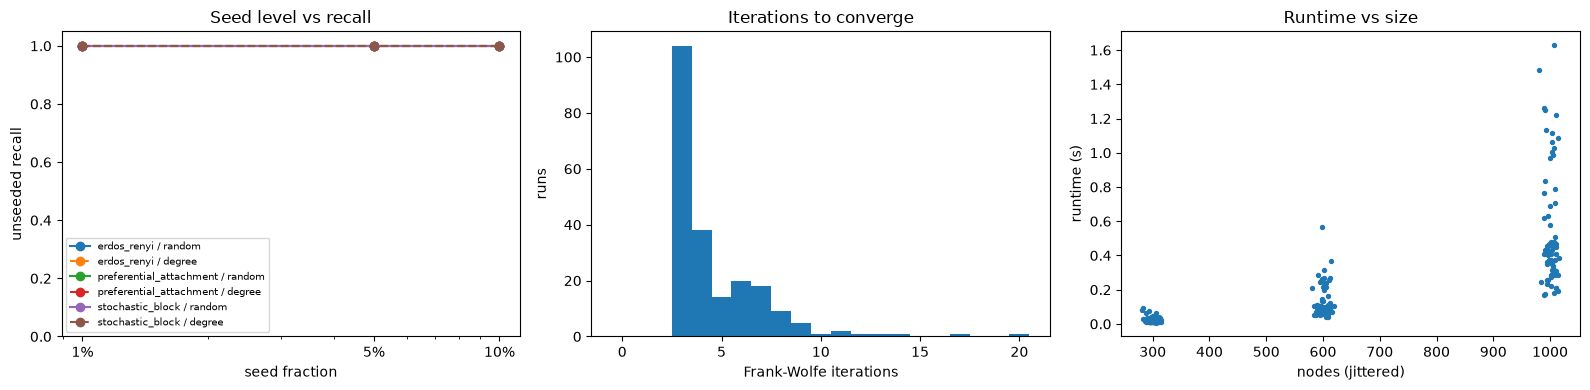

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for fam, g in sgm.groupby("family"):
    for kind, ls in (("random", "-"), ("degree", "--")):
        gg = g[g.seed_kind == kind].groupby("seed_pct").unseeded_recall.mean()
        ax[0].plot(gg.index, gg.values, ls, marker="o", label=f"{fam} / {kind}")
ax[0].set_xscale("log"); ax[0].set_xticks([1, 5, 10]); ax[0].set_xticklabels(["1%", "5%", "10%"])
ax[0].set_ylim(0, 1.05); ax[0].set_xlabel("seed fraction"); ax[0].set_ylabel("unseeded recall"); ax[0].set_title("Seed level vs recall"); ax[0].legend(fontsize=7)
ax[1].hist(sgm.iters, bins=np.arange(0, sgm.iters.max() + 2) - 0.5)
ax[1].set_xlabel("Frank-Wolfe iterations"); ax[1].set_ylabel("runs"); ax[1].set_title("Iterations to converge")
ax[2].scatter(sgm.n + np.random.default_rng(0).normal(0, 8, len(sgm)), sgm.runtime, s=8)
ax[2].set_xlabel("nodes (jittered)"); ax[2].set_ylabel("runtime (s)"); ax[2].set_title("Runtime vs size")
plt.tight_layout(); plt.savefig(FIGS / "experiments.png", dpi=130); plt.show()

## 6. Matching confidence and optimum check (Val)
- **Confidence:** the `score` of a match is its number of agreeing neighbour pairs under the final mapping. Keeping only matches with `score >= tau` trades coverage for precision (the task allows omitting uncertain nodes).
- **Optimiser or objective?** If SGM's mapping has a *lower* edge agreement than the ground-truth mapping, the optimiser got stuck in a local optimum; if it is *at least as high*, the objective itself cannot tell the true mapping apart.

**Precision vs coverage by agreement threshold (Val)**

kept  precision_of_kept
seeds     min_agreement                          
random 1% 0              1.000                1.0
          2              0.999                1.0
          3              0.997                1.0
          5              0.959                1.0
          8              0.804                1.0
          12             0.716                1.0
random 5% 0              1.000                1.0
          2              0.999                1.0
          3              0.997                1.0
          5              0.958                1.0
          8              0.804                1.0
          12             0.717                1.0

**Edge agreement of SGM's mapping vs the ground-truth mapping (Val)**

,mean_recall,mean_found_vs_truth,found_below_truth
seeds,,,
random 1%,1.0,1.0,0.0
random 5%,1.0,1.0,0.0


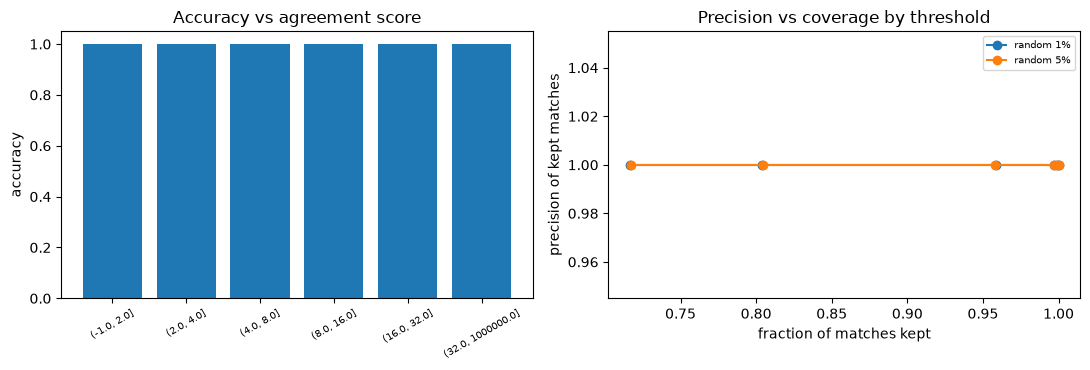

In [9]:
conf, obj = [], []
for pct in (1, 5):
    for name in list_instances("val"):
        A_, B_, s_, tr_, mt_ = load_instance("val", name, "random", pct)
        p_, inf_ = match_sgm(A_, B_, s_, **cfg)
        inf_["correct"] = [tr_[a] == b for a, b in zip(inf_.node_a, inf_.node_b)]
        inf_["pct"] = pct
        conf.append(inf_)
        f_found, f_true = edge_agreement(A_, B_, p_), edge_agreement(A_, B_, tr_)
        obj.append(dict(seeds=f"random {pct}%", instance=name, family=mt_["family"], f_found=f_found, f_truth=f_true,
                        found_vs_truth=f_found / f_true, unseeded_recall=evaluate(p_, tr_, s_, A_.shape[0])["unseeded_recall"],
                        iters=inf_.attrs["iters"]))
conf = pd.concat(conf, ignore_index=True)
obj = pd.DataFrame(obj)

q = []
for pct, g in conf.groupby("pct"):
    for thr in (0, 2, 3, 5, 8, 12):
        k = g[g.score >= thr]
        q.append(dict(seeds=f"random {pct}%", min_agreement=thr, kept=len(k) / len(g), precision_of_kept=k.correct.mean()))
q = pd.DataFrame(q)
display(Markdown("**Precision vs coverage by agreement threshold (Val)**")); display(q.set_index(["seeds", "min_agreement"]).round(3))
display(Markdown("**Edge agreement of SGM's mapping vs the ground-truth mapping (Val)**"))
display(obj.groupby("seeds").apply(lambda g: pd.Series(dict(mean_recall=g.unseeded_recall.mean(), mean_found_vs_truth=g.found_vs_truth.mean(),
                                                           found_below_truth=(g.found_vs_truth < 0.999).mean())), include_groups=False).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
bins = pd.cut(conf.score, [-1, 2, 4, 8, 16, 32, 1e6])
acc = conf.groupby(bins, observed=True).correct.mean()
ax[0].bar(range(len(acc)), acc.values); ax[0].set_xticks(range(len(acc))); ax[0].set_xticklabels([str(i) for i in acc.index], rotation=30, fontsize=7)
ax[0].set_ylim(0, 1.05); ax[0].set_ylabel("accuracy"); ax[0].set_title("Accuracy vs agreement score")
for seeds_, g in q.groupby("seeds"):
    ax[1].plot(g.kept, g.precision_of_kept, marker="o", label=seeds_)
ax[1].set_xlabel("fraction of matches kept"); ax[1].set_ylabel("precision of kept matches"); ax[1].legend(fontsize=7); ax[1].set_title("Precision vs coverage by threshold")
plt.tight_layout(); plt.savefig(FIGS / "confidence.png", dpi=130); plt.show()

## 7. Test predictions (frozen config)
The frozen configuration is read back from `config.json`; test truth does not exist locally and is never accessed. Seeds are part of the submitted mapping. The written files are re-read and checked against the submission format.

In [10]:
frozen = json.loads(Path("config.json").read_text())
sk, sp_ = frozen["submission_seeds"]["kind"], frozen["submission_seeds"]["pct"]
PRED = Path("predictions")
summary = []
for name in list_instances("test"):
    A_, B_, s_, _, mt_ = load_instance("test", name, sk, sp_)
    t = time.perf_counter()
    p_, inf_ = match_sgm(A_, B_, s_, **frozen["sgm_params"])
    dt = time.perf_counter() - t
    out = pd.DataFrame(sorted(p_.items()), columns=["node_a", "node_b"])
    (PRED / name).mkdir(parents=True, exist_ok=True)
    out.to_csv(PRED / name / "predictions.csv", index=False)
    summary.append(dict(instance=name, family=mt_["family"], difficulty=mt_["difficulty"], n=A_.shape[0], seeds=len(s_),
                        predicted=len(out), coverage=len(out) / A_.shape[0], iters=inf_.attrs["iters"], runtime=dt))
display(pd.DataFrame(summary).round(3))

for name in list_instances("test"):
    d = pd.read_csv(PRED / name / "predictions.csv")
    n_ = len(pd.read_csv(DATA / "test" / name / "nodes_a.csv"))
    s_ = load_instance("test", name, sk, sp_)[2]
    assert list(d.columns) == ["node_a", "node_b"] and d.node_a.is_unique and d.node_b.is_unique, name
    assert d.node_a.between(0, n_ - 1).all() and d.node_b.between(0, n_ - 1).all(), name
    assert all(dict(zip(d.node_a, d.node_b)).get(a) == b for a, b in s_.items()), name
print("OK:", len(list(PRED.glob("*/predictions.csv"))), "prediction files pass the format checks")

,instance,family,difficulty,n,seeds,predicted,coverage,iters,runtime
0,erdos_renyi_easy_00,erdos_renyi,easy,300,15,300,1.0,4,0.014
1,erdos_renyi_easy_01,erdos_renyi,easy,300,15,300,1.0,4,0.014
2,erdos_renyi_hard_00,erdos_renyi,hard,1000,50,1000,1.0,3,0.205
3,erdos_renyi_hard_01,erdos_renyi,hard,1000,50,1000,1.0,3,0.196
4,erdos_renyi_medium_00,erdos_renyi,medium,600,30,600,1.0,3,0.063
5,erdos_renyi_medium_01,erdos_renyi,medium,600,30,600,1.0,3,0.067
6,preferential_attachment_easy_00,preferential_attachment,easy,300,15,300,1.0,4,0.013
7,preferential_attachment_easy_01,preferential_attachment,easy,300,15,300,1.0,4,0.013
8,preferential_attachment_hard_00,preferential_attachment,hard,1000,50,1000,1.0,5,0.225
9,preferential_attachment_hard_01,preferential_attachment,hard,1000,50,1000,1.0,5,0.229


OK: 18 prediction files pass the format checks


## 8. Comparison with other methods
Each alternative runs on exactly the same 216 Train+Val runs (36 instances x 2 seed strategies x 3 seed levels). Their configurations were tuned on Train earlier with the same protocol and are fixed here (no re-tuning):

| method | idea | frozen config |
|---|---|---|
| **greedy percolation** | Every matched pair votes for its neighbour pairs; repeatedly match the unmatched pair with the most votes (>= `r`), then add its votes. Leftover Hungarian stage keeps pairs with >= `r_final` votes. | `r=1, margin=0, norm=none, r_final=1` |
| **iterative global** | Rounds of: vote matrix from current anchors -> one global assignment -> lock in the best `frac` of pairs with >= `tau` votes. | `tau=2, margin=0, frac=0.2, finish=False` |
| **one-shot seed-sim** | Describe each node by which seeds it touches; one global assignment on that similarity; keep pairs with similarity >= `tau`. | `kind=dot, idf=False, tau=1` |
| degree rank | Pair unseeded nodes by degree rank (weak floor). | - |
| seeds only | Submit the seeds (insufficient by the task rules). | - |

Per-instance rows of **all** methods (SGM included) are saved to `results/comparison_results.csv` (column `method`).

In [11]:
def percolate(A, B, seeds, r=2, margin=0, norm="none", r_final=None):
    """Greedy percolation."""
    n = A.shape[0]
    P = sp.csr_matrix((np.ones(len(seeds)), (list(seeds.keys()), list(seeds.values()))), shape=(n, n))
    Mraw = (A @ P @ B.T).toarray().astype(np.float32)
    dA = np.asarray(A.sum(1)).ravel()
    dB = np.asarray(B.sum(1)).ravel()
    scale = np.ones((n, n), np.float32)
    if norm == "deg":
        scale = (1.0 / np.sqrt(np.outer(np.maximum(dA, 1), np.maximum(dB, 1)))).astype(np.float32)
        scale *= np.sqrt(np.maximum(dA.mean(), 1) * np.maximum(dB.mean(), 1))
    tb = (-np.abs(dA[:, None] - dB[None, :]) / (max(dA.max(), dB.max()) + 1) * 0.5).astype(np.float32)
    used_a = np.zeros(n, bool); used_b = np.zeros(n, bool)
    dscore = np.full((n, n), -1.0, np.float32)  # rejection score
    pred = dict(seeds)
    for a, b in seeds.items():
        used_a[a] = used_b[b] = True
    log = []

    def priority(rows, cols):
        sub = Mraw[np.ix_(rows, cols)]
        ok = (sub >= r) & (sub > dscore[np.ix_(rows, cols)])
        ok &= ~used_a[rows][:, None] & ~used_b[cols][None, :]
        return np.where(ok, sub * scale[np.ix_(rows, cols)] + tb[np.ix_(rows, cols)], -np.inf)

    Q = priority(np.arange(n), np.arange(n))
    nbrs_a = lambda u: A.indices[A.indptr[u]:A.indptr[u + 1]]
    nbrs_b = lambda v: B.indices[B.indptr[v]:B.indptr[v + 1]]
    while True:
        k = int(Q.argmax()); u, v = divmod(k, n)
        if Q[u, v] == -np.inf:
            break
        s = float(Mraw[u, v]); gap = np.nan
        if margin > 0:
            row = Mraw[u].copy(); row[used_b] = -1; row[v] = -1
            col = Mraw[:, v].copy(); col[used_a] = -1; col[u] = -1
            gap = s - max(row.max(), col.max())
            if gap < margin:
                dscore[u, v] = s; Q[u, v] = -np.inf
                continue
        pred[u] = v
        used_a[u] = used_b[v] = True
        Q[u, :] = -np.inf; Q[:, v] = -np.inf
        log.append((u, v, s, gap))
        ra, cb = nbrs_a(u), nbrs_b(v)
        if len(ra) and len(cb):
            Mraw[np.ix_(ra, cb)] += 1
            Q[np.ix_(ra, cb)] = priority(ra, cb)
    if r_final is not None:
        ua, ub = np.where(~used_a)[0], np.where(~used_b)[0]
        if len(ua) and len(ub):
            sub = Mraw[np.ix_(ua, ub)]
            ri, ci = linear_sum_assignment(-sub)
            for i, j in zip(ri, ci):
                if sub[i, j] >= r_final:
                    pred[int(ua[i])] = int(ub[j]); log.append((int(ua[i]), int(ub[j]), float(sub[i, j]), np.nan))
    return pred, pd.DataFrame(log, columns=["node_a", "node_b", "score", "gap"])


def match_iter(A, B, seeds, tau=1, margin=1, frac=1.0, finish=False, max_rounds=300):
    """Iterative global assignment."""
    n = A.shape[0]
    Ac, Bc = A.tocsc(), B.tocsc()
    dA = np.asarray(A.sum(1)).ravel(); dB = np.asarray(B.sum(1)).ravel()
    tb = (-np.abs(dA[:, None] - dB[None, :]) / (max(dA.max(), dB.max()) + 1) * 1e-3).astype(np.float32)
    P = sp.csr_matrix((np.ones(len(seeds)), (list(seeds.keys()), list(seeds.values()))), shape=(n, n))
    M = (A @ P @ B.T).toarray().astype(np.float32)
    used_a = np.zeros(n, bool); used_b = np.zeros(n, bool)
    for a, b in seeds.items():
        used_a[a] = used_b[b] = True
    pred, log = dict(seeds), []

    def assign():
        ua, ub = np.where(~used_a)[0], np.where(~used_b)[0]
        Su = M[np.ix_(ua, ub)]
        ri, ci = linear_sum_assignment(-(Su + tb[np.ix_(ua, ub)]))
        s = Su[ri, ci]
        if Su.shape[0] > 1 and Su.shape[1] > 1:  # row/col runner-up
            p = np.partition(Su, -2, axis=1)[:, -2:]; rmax, rsec = p.max(1), p.min(1)
            p = np.partition(Su, -2, axis=0)[-2:, :]; cmax, csec = p.max(0), p.min(0)
            alt = np.maximum(np.where(s >= rmax[ri], rsec[ri], rmax[ri]), np.where(s >= cmax[ci], csec[ci], cmax[ci]))
        else:
            alt = np.zeros_like(s)
        return ua[ri], ub[ci], s, s - alt

    rnd = 0
    for rnd in range(1, max_rounds + 1):
        if used_a.all():
            break
        ra, cb, s, gap = assign()
        idx = np.where((s >= tau) & (gap >= margin))[0]
        if len(idx) == 0:
            break
        if frac < 1:
            idx = idx[np.lexsort((-s[idx], -gap[idx]))][: max(1, int(np.ceil(frac * len(idx))))]
        la, lb = ra[idx], cb[idx]
        for u, v, sc, g in zip(la, lb, s[idx], gap[idx]):
            pred[int(u)] = int(v); log.append((int(u), int(v), float(sc), float(g), rnd))
        used_a[la] = used_b[lb] = True
        M += (Ac[:, la] @ Bc[:, lb].T).toarray().astype(np.float32)
    if finish and not used_a.all():
        ra, cb, s, gap = assign()
        for u, v, sc, g in zip(ra, cb, s, gap):
            if sc >= tau:
                pred[int(u)] = int(v); log.append((int(u), int(v), float(sc), float(g), rnd + 1))
    return pred, pd.DataFrame(log, columns=["node_a", "node_b", "score", "gap", "round"])


def match_seed_sim(A, B, seeds, kind="dot", idf=False, tau=None):
    """One-shot seed-adjacency similarity."""
    n = A.shape[0]
    sa, sb = list(seeds.keys()), list(seeds.values())
    Xa = A[:, sa].toarray().astype(np.float32); Xb = B[:, sb].toarray().astype(np.float32)
    dA = np.asarray(A.sum(1)).ravel(); dB = np.asarray(B.sum(1)).ravel()
    if idf and kind != "jaccard":
        w = (1.0 / np.log(1.0 + (dA[sa] + dB[sb]) / 2.0)).astype(np.float32)
        Xa, Xb = Xa * w, Xb * w
    inter = Xa @ Xb.T
    if kind == "dot":
        S = inter
    elif kind == "cosine":
        S = inter / np.maximum(np.linalg.norm(Xa, axis=1, keepdims=True) * np.linalg.norm(Xb, axis=1, keepdims=True).T, 1e-9)
    else:  # jaccard
        S = inter / np.maximum(Xa.sum(1, keepdims=True) + Xb.sum(1, keepdims=True).T - inter, 1e-9)
    ua = np.array([u for u in range(n) if u not in seeds])
    used_b = set(seeds.values())
    ub = np.array([v for v in range(n) if v not in used_b])
    Su = S[np.ix_(ua, ub)]
    tb = -np.abs(dA[ua][:, None] - dB[ub][None, :]) / (max(dA.max(), dB.max()) + 1) * 1e-3
    ri, ci = linear_sum_assignment(-(Su + tb))
    pred, log = dict(seeds), []
    for i, j in zip(ri, ci):
        if tau is None or Su[i, j] >= tau:
            pred[int(ua[i])] = int(ub[j]); log.append((int(ua[i]), int(ub[j]), float(Su[i, j])))
    return pred, pd.DataFrame(log, columns=["node_a", "node_b", "score"])


def degree_rank_baseline(A, B, seeds):
    """Pair unseeded nodes by degree rank."""
    da = np.asarray(A.sum(1)).ravel(); db = np.asarray(B.sum(1)).ravel()
    ua = [u for u in np.argsort(-da, kind="stable") if u not in seeds]
    used_b = set(seeds.values())
    ub = [v for v in np.argsort(-db, kind="stable") if v not in used_b]
    pred = dict(seeds); pred.update(zip(ua, ub))
    return pred, None


METHODS.update(perc=percolate, iter=match_iter, sim=match_seed_sim, degree_rank=degree_rank_baseline)
COMPARE_CFGS = {
    "perc": dict(r=1, margin=0, norm="none", r_final=1),
    "iter": dict(tau=2, margin=0, frac=0.2, finish=False),
    "sim": dict(kind="dot", idf=False, tau=1),
}

In [12]:
frames = [sgm]
for split in ("train", "val"):
    for method, c in COMPARE_CFGS.items():
        frames.append(run_grid(split, ALL_SETTINGS, [c], method=method))
    for method in ("degree_rank", "seeds_only"):
        frames.append(run_grid(split, [("random", 5)], [{}], method=method))
allres = pd.concat(frames, ignore_index=True)
allres.to_csv(RESULTS / "comparison_results.csv", index=False)
print(len(allres), "runs saved to results/comparison_results.csv")

LABELS = {"sgm": "SGM (main)", "perc": "greedy percolation", "iter": "iterative global", "sim": "one-shot seed-sim",
          "degree_rank": "degree rank", "seeds_only": "seeds only"}
main4 = allres[allres.method.isin(["sgm", "perc", "iter", "sim"])]
order = [LABELS[m] for m in ("sgm", "perc", "iter", "sim")]
piv = lambda col: (main4.pivot_table(index=["seed_kind", "seed_pct"], columns="method", values=col)
                   .rename(columns=LABELS)[order].round(3))
display(Markdown("**Unseeded recall by seed setting (Train+Val, mean over instances)**")); display(piv("unseeded_recall"))
display(Markdown("**Unseeded precision by seed setting**")); display(piv("unseeded_precision"))
display(Markdown("**Coverage by seed setting**")); display(piv("coverage"))
display(Markdown("**All methods incl. baselines at 5% random seeds**"))
display(allres[(allres.seed_pct == 5) & (allres.seed_kind == "random")].groupby("method")[["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage", "runtime"]]
        .mean().rename(index=LABELS).sort_values("unseeded_f1", ascending=False).round(3))
display(Markdown("**Unseeded recall by family at 1% random seeds**"))
display(main4[(main4.seed_pct == 1) & (main4.seed_kind == "random")].pivot_table(index="family", columns="method", values="unseeded_recall")
        .rename(columns=LABELS)[order].round(3))
display(Markdown("**Runtime per instance by size (seconds)**"))
display(main4.pivot_table(index="n", columns="method", values="runtime").rename(columns=LABELS)[order].round(3))

keys = ["split", "instance", "seed_kind", "seed_pct"]
w = main4.pivot_table(index=keys, columns="method", values="unseeded_recall").reset_index()
display(Markdown("**SGM vs each method, per run: share where SGM is better / equal (within 0.005) / worse**"))
display(pd.DataFrame({LABELS[m]: dict(better=((w.sgm - w[m]) > 0.005).mean(), equal=((w.sgm - w[m]).abs() <= 0.005).mean(),
                                      worse=((w.sgm - w[m]) < -0.005).mean()) for m in ("perc", "iter", "sim")}).T.round(2))

936 runs saved to results/comparison_results.csv


**Unseeded recall by seed setting (Train+Val, mean over instances)**

method              SGM (main)  greedy percolation  iterative global  one-shot seed-sim
seed_kind seed_pct                                                                     
degree    1                1.0               0.979             0.916              0.073
          5                1.0               1.000             1.000              0.566
          10               1.0               1.000             1.000              0.879
random    1                1.0               0.913             0.848              0.044
          5                1.0               1.000             0.999              0.365
          10               1.0               1.000             1.000              0.681

**Unseeded precision by seed setting**

method              SGM (main)  greedy percolation  iterative global  one-shot seed-sim
seed_kind seed_pct                                                                     
degree    1                1.0               0.979             0.922              0.180
          5                1.0               1.000             1.000              0.656
          10               1.0               1.000             1.000              0.915
random    1                1.0               0.913             0.880              0.246
          5                1.0               1.000             0.999              0.536
          10               1.0               1.000             1.000              0.795

**Coverage by seed setting**

... (5 outputs left out)

**Runtime per instance by size (seconds)**

method,SGM (main),greedy percolation,iterative global,one-shot seed-sim
n,,,,
300,0.023,0.023,0.017,0.002
600,0.129,0.141,0.062,0.008
1000,0.537,0.583,0.214,0.030


**SGM vs each method, per run: share where SGM is better / equal (within 0.005) / worse**

,better,equal,worse
greedy percolation,0.13,0.87,0.0
iterative global,0.26,0.74,0.0
one-shot seed-sim,1.00,0.00,0.0


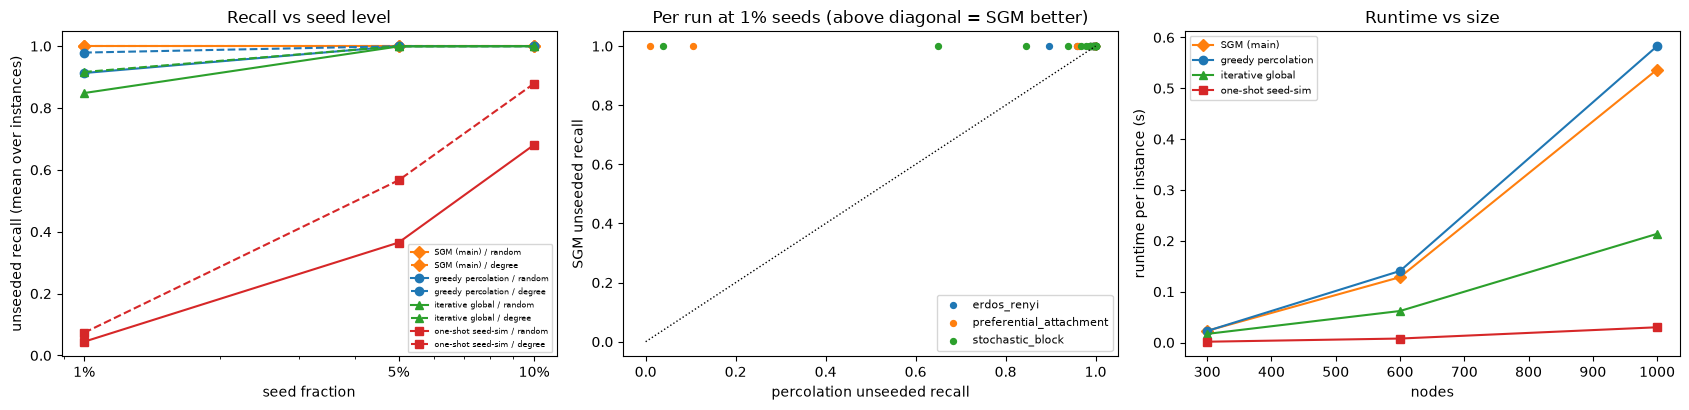

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
styles = {"sgm": ("C1", "D"), "perc": ("C0", "o"), "iter": ("C2", "^"), "sim": ("C3", "s")}
for m, (c, mk) in styles.items():
    for kind, ls in (("random", "-"), ("degree", "--")):
        g = main4[(main4.method == m) & (main4.seed_kind == kind)].groupby("seed_pct").unseeded_recall.mean()
        ax[0].plot(g.index, g.values, ls, marker=mk, c=c, label=f"{LABELS[m]} / {kind}")
ax[0].set_xscale("log"); ax[0].set_xticks([1, 5, 10]); ax[0].set_xticklabels(["1%", "5%", "10%"])
ax[0].set_xlabel("seed fraction"); ax[0].set_ylabel("unseeded recall (mean over instances)"); ax[0].legend(fontsize=6); ax[0].set_title("Recall vs seed level")
w1 = w[w.seed_pct == 1].merge(main4[["instance", "family"]].drop_duplicates(), on="instance")
for fam, g in w1.groupby("family"):
    ax[1].scatter(g.perc, g.sgm, label=fam, s=18)
ax[1].plot([0, 1], [0, 1], "k:", lw=1); ax[1].set_xlabel("percolation unseeded recall"); ax[1].set_ylabel("SGM unseeded recall")
ax[1].set_title("Per run at 1% seeds (above diagonal = SGM better)"); ax[1].legend(fontsize=8)
for m, (c, mk) in styles.items():
    g = main4[main4.method == m].groupby("n").runtime.mean()
    ax[2].plot(g.index, g.values, marker=mk, c=c, label=LABELS[m])
ax[2].set_xlabel("nodes"); ax[2].set_ylabel("runtime per instance (s)"); ax[2].set_title("Runtime vs size"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIGS / "comparison.png", dpi=130); plt.show()

## Takeaways

**Result.** SGM recovers the full mapping in every one of the 216 Train+Val runs (36 instances x random/degree seeds x 1/5/10%): precision, recall, F1, coverage and unseeded recall are all 1.000, including at 1% seeds (3 to 10 pairs) and on every family and difficulty. Test predictions are written for all 18 Test instances at 5% random seeds with the frozen configuration (`init=bary`, `max_iter=30`), all with full coverage.

**Why it works.** The objective scores a mapping by the agreement of *all* edges, so unseeded nodes constrain each other from the first iteration; the seeds only need to break the graph's symmetries. On every Val instance (1% and 5% random seeds) the edge agreement of SGM's mapping equals that of the ground truth: the optimiser reaches the optimum and that optimum is the true mapping.

**Tuning (Train only).** Barycentre and 50/50 mix starts with up to 30 iterations both reach F1 1.000 on Train; barycentre is first in the sorted table and was frozen. A cap of 10 iterations is slightly too few (F1 0.97 to 0.99), and the pure vote-based start is slightly worse (0.98). Convergence takes about 7 iterations at 1% seeds and 3 at 5 to 10% (max 20, the cap of 30 was never hit).

**Confidence.** The agreement score of a match is a usable confidence signal, but on these graphs every match is already correct: `score >= 8` keeps 80% of nodes at precision 1.000. A rejection threshold would only cost coverage here, so none is used.

**Runtime.** About 0.02 s (n=300), 0.13 s (n=600) and 0.54 s (n=1000) per instance, the same order as greedy percolation.

**Comparison (section 8).** Mean unseeded recall over Train+Val:

| seeds | SGM | greedy percolation | iterative global | one-shot seed-sim |
|---|---|---|---|---|
| 1% random | 1.000 | 0.913 | 0.848 | 0.044 |
| 1% degree | 1.000 | 0.979 | 0.916 | 0.073 |
| 5% random / degree | 1.000 / 1.000 | 1.000 / 1.000 | 0.999 / 1.000 | 0.365 / 0.566 |
| 10% random / degree | 1.000 / 1.000 | 1.000 / 1.000 | 1.000 / 1.000 | 0.681 / 0.879 |

- **SGM is never worse** than any alternative on any run. At 1% seeds it is better than percolation on 39% of runs and better than iterative global on 75%; at 5% and above the iterative methods tie with it.
- **Percolation and iterative global** grow the matching only from edges next to already-matched pairs, so with very few seeds they can fail to ignite (worst: preferential attachment at 1% random seeds, 0.84 and 0.75 recall). Iterative global locks in some wrong pairs in its first rounds and those errors feed later rounds.
- **One-shot seed-sim** only sees direct adjacency to the given seeds; nodes that touch no seed are indistinguishable, so it never comes close (0.37 recall at 5% random seeds). It is the fastest (0.03 s at n=1000).
- **Baselines** at 5% random seeds: degree rank 0.018 unseeded recall, seeds only 0.

**Limitations.**
- Train/Val are at ceiling, so they cannot separate SGM from a perfect method; sparser, noisier graphs or fewer than 1% seeds would be needed to find its limits (not tested).
- The objective is non-convex and Frank-Wolfe is a local search; it found the global optimum on all 54 graph pairs here, which is not a guarantee for unseen graphs.
- Dense n x n gradient and assignment problems: memory O(n^2) and a cubic-time assignment per iteration; fine up to n around 1000.
- Assumes B has the same node set as A with edge-perturbation noise only.
- Submission uses 5% random seeds for every Test instance (assumption); Test accuracy cannot be checked locally.
- Privacy implication: a handful of known correspondences plus structure alone are enough to de-anonymize these graphs completely.